In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse.linalg import svds
from scipy.sparse import coo_matrix
from sklearn.model_selection import train_test_split
import math
import time
import os

In [ ]:
# Set random seeds for reproducibility
np.random.seed(42)

# ==============================================================================
# 1. DATASET SETUP (MovieLens 1M)
# ==============================================================================

dataset_zip = 'ml-1m.zip'
dataset_folder = 'ml-1m'

if not os.path.exists(dataset_zip) and not os.path.exists(dataset_folder):
    print("Downloading MovieLens 1M (Big Data)...")
    !wget -q https://files.grouplens.org/datasets/movielens/ml-1m.zip
    !unzip -q -o ml-1m.zip
elif os.path.exists(dataset_zip) and not os.path.exists(dataset_folder):
    print("Dataset zip found, unzipping...")
    !unzip -q -o ml-1m.zip
else:
    print("MovieLens 1M dataset already downloaded and extracted.")

print("Loading data into memory...")
ratings_df = pd.read_csv('ml-1m/ratings.dat', sep='::', engine='python',
                         names=['userId', 'movieId', 'rating', 'timestamp'])

n_ratings = len(ratings_df)
user_ids = ratings_df['userId'].unique()
movie_ids = ratings_df['movieId'].unique()
user_to_idx = {id: i for i, id in enumerate(user_ids)}
movie_to_idx = {id: i for i, id in enumerate(movie_ids)}

n_users = len(user_ids)
n_movies = len(movie_ids)
density = (n_ratings / (n_users * n_movies)) * 100
sparsity = 100 - density

print(f"Matrix Dimensions: {n_users} Users x {n_movies} Movies")
print(f"Sparsity: {sparsity:.2f}% (Highly sparse!)")

Loading data into memory...
Matrix Dimensions: 6040 Users x 3706 Movies
Sparsity: 95.53% (Highly sparse!)


In [ ]:
print("\n--- ratings_df info ---")
ratings_df.info()
print("\n--- ratings_df head ---")
print(ratings_df.head())
print("\n--- ratings_df describe ---")
print(ratings_df.describe())

if 'movies_df' in locals():
    print("\n--- movies_df info ---")
    movies_df.info()
    print("\n--- movies_df head ---")
    print(movies_df.head())
    print("\n--- movies_df describe ---")
    print(movies_df.describe())
else:
    print("\nmovies_df not yet loaded in this scope. It will be loaded in Phase 4.")


--- ratings_df info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   userId     1000209 non-null  int64
 1   movieId    1000209 non-null  int64
 2   rating     1000209 non-null  int64
 3   timestamp  1000209 non-null  int64
dtypes: int64(4)
memory usage: 30.5 MB

--- ratings_df head ---
   userId  movieId  rating  timestamp
0       1     1193       5  978300760
1       1      661       3  978302109
2       1      914       3  978301968
3       1     3408       4  978300275
4       1     2355       5  978824291

--- ratings_df describe ---
             userId       movieId        rating     timestamp
count  1.000209e+06  1.000209e+06  1.000209e+06  1.000209e+06
mean   3.024512e+03  1.865540e+03  3.581564e+00  9.722437e+08
std    1.728413e+03  1.096041e+03  1.117102e+00  1.215256e+07
min    1.000000e+00  1.000000e+00  1.000000e+00  9.567

In [ ]:
# Convert to numpy arrays
users = np.array([user_to_idx[u] for u in ratings_df['userId']])
movies = np.array([movie_to_idx[m] for m in ratings_df['movieId']])
ratings = np.array(ratings_df['rating'], dtype=np.float32)

In [ ]:
# Create Sparse Matrix for SVD
R_sparse = coo_matrix((ratings, (users, movies)), shape=(n_users, n_movies))
print(f"Sparse Matrix Shape: {R_sparse.shape}")
print(f"Number of Non-Zero Elements: {R_sparse.nnz}")

Sparse Matrix Shape: (6040, 3706)
Number of Non-Zero Elements: 1000209


Set the Train/Validation/Test Split (80/10/10)

In [ ]:
# Train/Validation/Test Split (80/10/10)
train_idx, temp_idx = train_test_split(np.arange(n_ratings), test_size=0.2, random_state=42)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, random_state=42)

train_users, train_movies, train_ratings = users[train_idx], movies[train_idx], ratings[train_idx]
val_users, val_movies, val_ratings = users[val_idx], movies[val_idx], ratings[val_idx]
test_users, test_movies, test_ratings = users[test_idx], movies[test_idx], ratings[test_idx]

print(f"Train samples: {len(train_idx)}, Validation samples: {len(val_idx)}, Test samples: {len(test_idx)}")


Train samples: 800167, Validation samples: 100021, Test samples: 100021


In [ ]:
#Print the total of the 3 sets to check: REMOVE LATER
print(f"Total samples: {len(train_idx) + len(val_idx) + len(test_idx)}")

Total samples: 1000209


In [ ]:
# ==============================================================================
# 2. CORE ALGORITHMS
# ==============================================================================

def get_rmse(U, V, t_users, t_movies, t_ratings):
    """Computes the Root Mean Squared Error (RMSE) for the predictions."""
    preds = np.sum(U[t_users] * V[t_movies], axis=1)
    errors = t_ratings - preds
    return math.sqrt(np.mean(errors**2))


def spectral_initialization(R_sparse, rank):
    """Initializes latent factor matrices U and V using truncated SVD."""
    print(f"   [Init] Executing Truncated SVD (Rank={rank})...")
    u, s, vt = svds(R_sparse, k=rank)
    S_sqrt = np.diag(np.sqrt(s))
    U_init = np.dot(u, S_sqrt)
    V_init = np.dot(vt.T, S_sqrt)
    return U_init[:, ::-1], V_init[:, ::-1]


def run_sgd_optimized(n_u, n_m, rank, init_method, R_sparse,
                      t_users, t_movies, t_ratings,
                      val_users, val_movies, val_ratings,
                      steps=15, alpha=0.005, beta=0.02, tolerance=0.01):
    """
    Trains the matrix factorization model using Stochastic Gradient Descent (SGD).
    Includes early stopping based on validation RMSE convergence.
    """
    if init_method == 'spectral':
        U, V = spectral_initialization(R_sparse, rank)
    else:
        U = np.random.normal(scale=1./rank, size=(n_u, rank))
        V = np.random.normal(scale=1./rank, size=(n_m, rank))

    history = []
    print(f"   [Training] Start ({init_method}, Rank={rank}, a={alpha}, b={beta})...")

    prev_rmse = float('inf')

    for step in range(steps):
        shuffled_indices = np.random.permutation(len(t_ratings))

        # SGD Update Loop
        for idx in shuffled_indices:
            u = t_users[idx]
            i = t_movies[idx]
            r = t_ratings[idx]

            pred = np.dot(U[u], V[i])
            err = r - pred

            u_vec = U[u]
            v_vec = V[i]

            U[u] += alpha * (err * v_vec - beta * u_vec)
            V[i] += alpha * (err * u_vec - beta * v_vec)

        rmse_train = get_rmse(U, V, t_users, t_movies, t_ratings)
        rmse_val = get_rmse(U, V, val_users, val_movies, val_ratings)
        history.append(rmse_val)
        print(f"   -> Epoch {step+1}: Train RMSE = {rmse_train:.4f}, Val RMSE = {rmse_val:.4f}")

        # Early Stopping Check
        if prev_rmse - rmse_val < tolerance:
            print(f"   -> Converged at Epoch {step+1}")
            break
        prev_rmse = rmse_val

    return history, U, V

FASE 1: SPETTRALE VS RANDOM


PHASE 1: INITIALIZATION COMPARISON (Random vs Spectral)
Fixed Parameters: Rank=50, Alpha=0.005, Beta=0.02

--- Training with Random Initialization ---
   [Training] Start (random, Rank=50, a=0.005, b=0.02)...
   -> Epoch 1: Train RMSE = 2.1157, Val RMSE = 2.1264
   -> Epoch 2: Train RMSE = 1.1004, Val RMSE = 1.1183
   -> Epoch 3: Train RMSE = 0.9759, Val RMSE = 0.9926
   -> Epoch 4: Train RMSE = 0.9392, Val RMSE = 0.9557
   -> Epoch 5: Train RMSE = 0.9229, Val RMSE = 0.9394
   -> Epoch 6: Train RMSE = 0.9126, Val RMSE = 0.9307
   -> Converged at Epoch 6

--- Training with Spectral Initialization ---
   [Init] Executing Truncated SVD (Rank=50)...
   [Training] Start (spectral, Rank=50, a=0.005, b=0.02)...
   -> Epoch 1: Train RMSE = 1.1261, Val RMSE = 1.2018
   -> Epoch 2: Train RMSE = 0.9203, Val RMSE = 1.0147
   -> Epoch 3: Train RMSE = 0.8381, Val RMSE = 0.9416
   -> Epoch 4: Train RMSE = 0.7955, Val RMSE = 0.9062
   -> Epoch 5: Train RMSE = 0.7685, Val RMSE = 0.8853
   -> Epoch 6: 

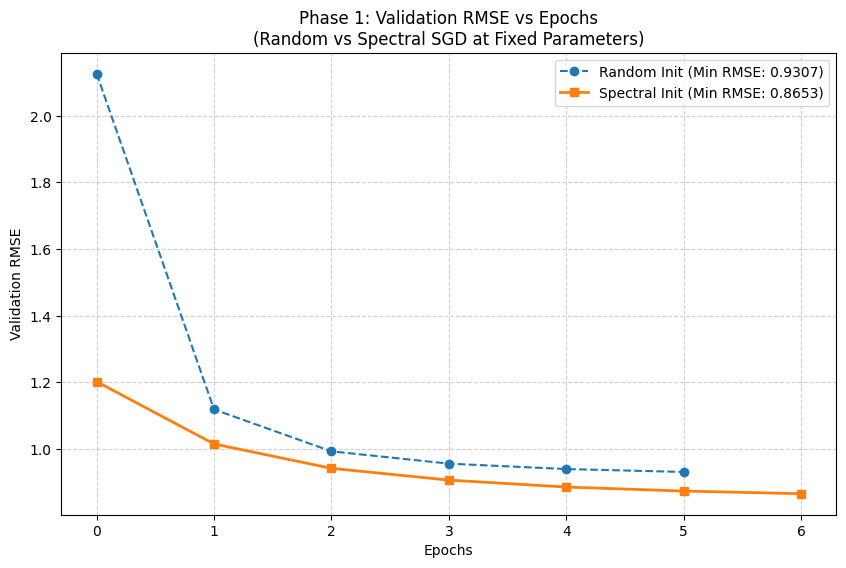


Final Random RMSE:   0.9307
Final Spectral RMSE: 0.8653
-> Conclusion: Spectral Initialization converges better/faster.
-> Proceeding with ONLY Spectral Initialization for the next phases.



In [ ]:
# ==============================================================================
# PHASE 1: INITIALIZATION COMPARISON (Random vs Spectral)
# Fixing parameters to prove the superiority of Spectral Initialization.
# ==============================================================================
import matplotlib.pyplot as plt

print("\n" + "="*60)
print("PHASE 1: INITIALIZATION COMPARISON (Random vs Spectral)")
print("Fixed Parameters: Rank=50, Alpha=0.005, Beta=0.02")
print("="*60)

# Neutral baseline parameters
TEST_RANK = 50
TEST_ALPHA = 0.005
TEST_BETA = 0.02
TEST_STEPS = 20

# 1. Training with Random Initialization
print("\n--- Training with Random Initialization ---")
hist_rnd, _, _ = run_sgd_optimized(n_users, n_movies, TEST_RANK, 'random', R_sparse,
                                   train_users, train_movies, train_ratings,
                                   val_users, val_movies, val_ratings,
                                   steps=TEST_STEPS, alpha=TEST_ALPHA, beta=TEST_BETA)

# 2. Training with Spectral Initialization
print("\n--- Training with Spectral Initialization ---")
hist_spec, _, _ = run_sgd_optimized(n_users, n_movies, TEST_RANK, 'spectral', R_sparse,
                                    train_users, train_movies, train_ratings,
                                    val_users, val_movies, val_ratings,
                                    steps=TEST_STEPS, alpha=TEST_ALPHA, beta=TEST_BETA)

# 3. Plotting the Learning Curves

plt.figure(figsize=(10, 6))
plt.plot(hist_rnd, label=f'Random Init (Min RMSE: {min(hist_rnd):.4f})', marker='o', linestyle='--', color='tab:blue')
plt.plot(hist_spec, label=f'Spectral Init (Min RMSE: {min(hist_spec):.4f})', marker='s', linestyle='-', color='tab:orange', linewidth=2)

plt.title('Phase 1: Validation RMSE vs Epochs\n(Random vs Spectral SGD at Fixed Parameters)')
plt.xlabel('Epochs')
plt.ylabel('Validation RMSE')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print(f"\nFinal Random RMSE:   {min(hist_rnd):.4f}")
print(f"Final Spectral RMSE: {min(hist_spec):.4f}")
print("-> Conclusion: Spectral Initialization converges better/faster.")
print("-> Proceeding with ONLY Spectral Initialization for the next phases.\n")

Fase 2: confronta cosa succede al variare dei parametri
Qui si confronta la LEARNING RATE ALPHA

PHASE 2: 2D GRID SEARCH (ALPHA x BETA) AT FIXED RANK
training Alpha=0.001, Beta=0.01...
   [Init] Executing Truncated SVD (Rank=50)...
   [Training] Start (spectral, Rank=50, a=0.001, b=0.01)...
   -> Epoch 1: Train RMSE = 1.7552, Val RMSE = 1.7786
   -> Epoch 2: Train RMSE = 1.4959, Val RMSE = 1.5407
   -> Epoch 3: Train RMSE = 1.3331, Val RMSE = 1.3925
   -> Epoch 4: Train RMSE = 1.2210, Val RMSE = 1.2907
   -> Epoch 5: Train RMSE = 1.1389, Val RMSE = 1.2165
   -> Epoch 6: Train RMSE = 1.0762, Val RMSE = 1.1599
   -> Epoch 7: Train RMSE = 1.0270, Val RMSE = 1.1156
   -> Epoch 8: Train RMSE = 0.9874, Val RMSE = 1.0803
   -> Epoch 9: Train RMSE = 0.9549, Val RMSE = 1.0514
   -> Epoch 10: Train RMSE = 0.9279, Val RMSE = 1.0276
   -> Epoch 11: Train RMSE = 0.9051, Val RMSE = 1.0076
   -> Epoch 12: Train RMSE = 0.8856, Val RMSE = 0.9907
   -> Epoch 13: Train RMSE = 0.8687, Val RMSE = 0.9764
   -> Epoch 14: Train RMSE = 0.8541, Val RMSE = 0.9639
   -> Epoch 15: Train RMSE = 0.8412, Val RMS

/tmp/ipykernel_175/76235420.py:63: RuntimeWarning: overflow encountered in multiply
  U[u] += alpha * (err * v_vec - beta * u_vec)
/tmp/ipykernel_175/76235420.py:64: RuntimeWarning: overflow encountered in multiply
  V[i] += alpha * (err * u_vec - beta * v_vec)


   -> Epoch 1: Train RMSE = nan, Val RMSE = nan
   -> Epoch 2: Train RMSE = nan, Val RMSE = nan
   -> Epoch 3: Train RMSE = nan, Val RMSE = nan
   -> Epoch 4: Train RMSE = nan, Val RMSE = nan
   -> Epoch 5: Train RMSE = nan, Val RMSE = nan
   -> Epoch 6: Train RMSE = nan, Val RMSE = nan
   -> Epoch 7: Train RMSE = nan, Val RMSE = nan
   -> Epoch 8: Train RMSE = nan, Val RMSE = nan
   -> Epoch 9: Train RMSE = nan, Val RMSE = nan
   -> Epoch 10: Train RMSE = nan, Val RMSE = nan
   -> Epoch 11: Train RMSE = nan, Val RMSE = nan
   -> Epoch 12: Train RMSE = nan, Val RMSE = nan
   -> Epoch 13: Train RMSE = nan, Val RMSE = nan
   -> Epoch 14: Train RMSE = nan, Val RMSE = nan
   -> Epoch 15: Train RMSE = nan, Val RMSE = nan
   -> Epoch 16: Train RMSE = nan, Val RMSE = nan
   -> Epoch 17: Train RMSE = nan, Val RMSE = nan
   -> Epoch 18: Train RMSE = nan, Val RMSE = nan
   -> Epoch 19: Train RMSE = nan, Val RMSE = nan
   -> Epoch 20: Train RMSE = nan, Val RMSE = nan
training Alpha=0.02, Beta=0.0

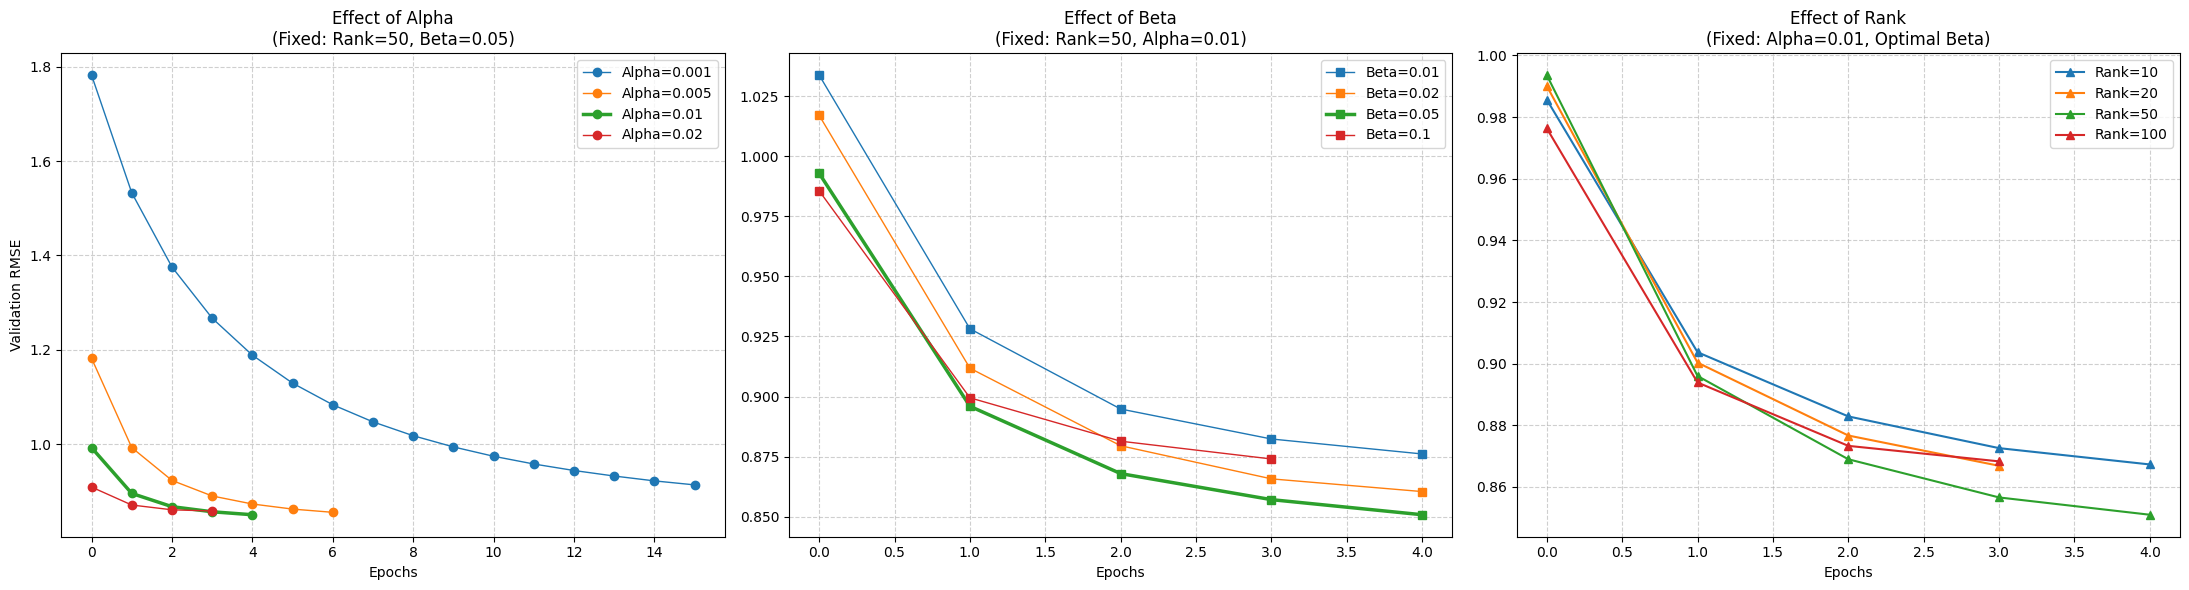


FINAL OPTIMAL PARAMETERS: Rank=50, Alpha=0.01, Beta=0.05


In [ ]:
# ==============================================================================
# PHASE 2 & 3: RIGOROUS GRID SEARCH & LEARNING CURVES
# ==============================================================================
import matplotlib.pyplot as plt

print("="*60)
print("PHASE 2: 2D GRID SEARCH (ALPHA x BETA) AT FIXED RANK")
print("="*60)

FIXED_RANK = 50
SWEEP_EPOCHS = 20
alphas_to_test = [0.001, 0.005, 0.01, 0.02]
betas_to_test = [0.01, 0.02, 0.05, 0.1]

best_alpha = None
best_beta = None
min_grid_rmse = float('inf')

# dictionary for saving the curves without having to calculate them again
history_dict = {}

# 1. GRID SEARCH
for a in alphas_to_test:
    for b in betas_to_test:
        print(f"training Alpha={a}, Beta={b}...")
        hist, _, _ = run_sgd_optimized(n_users, n_movies, FIXED_RANK, 'spectral', R_sparse,
                                       train_users, train_movies, train_ratings,
                                       val_users, val_movies, val_ratings,
                                       steps=SWEEP_EPOCHS, alpha=a, beta=b)
        history_dict[(a, b)] = hist

        if min(hist) < min_grid_rmse:
            min_grid_rmse = min(hist)
            best_alpha = a
            best_beta = b

print("\n" + "-"*40)
print(f"OPTIMAL PAIR AT RANK 50: Alpha={best_alpha}, Beta={best_beta}")
print("-" * 40 + "\n")


print("="*60)
print("PHASE 3: GENERATING SENSITIVITY CURVES")
print("="*60)

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# --- PLOT 1: EFFECT OF ALPHA (holding best_beta constant) ---
for a in alphas_to_test:
    curve = history_dict[(a, best_beta)]
    linewidth = 2.5 if a == best_alpha else 1.0
    axes[0].plot(curve, marker='o', linewidth=linewidth, label=f'Alpha={a}')

axes[0].set_title(f"Effect of Alpha\n(Fixed: Rank=50, Beta={best_beta})")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Validation RMSE")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# --- PLOT 2: EFFECT OF BETA (holding best_alpha constant) ---
for b in betas_to_test:
    curve = history_dict[(best_alpha, b)]
    linewidth = 2.5 if b == best_beta else 1.0
    axes[1].plot(curve, marker='s', linewidth=linewidth, label=f'Beta={b}')

axes[1].set_title(f"Effect of Beta\n(Fixed: Rank=50, Alpha={best_alpha})")
axes[1].set_xlabel("Epochs")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

# --- PLOT 3: EFFECT OF RANK (using optimal alpha and beta) ---
print("\ntesting different ranks using optimal alpha and beta...")
ranks_to_test = [10, 20, 50, 100]
best_rank = None
min_rank_rmse = float('inf')

for r in ranks_to_test:
    # heuristics to prevent overfitting on high ranks
    current_beta = best_beta if r <= 50 else best_beta * 2

    print(f"running Rank={r} (Beta={current_beta})...")
    hist, _, _ = run_sgd_optimized(n_users, n_movies, r, 'spectral', R_sparse,
                                   train_users, train_movies, train_ratings,
                                   val_users, val_movies, val_ratings,
                                   steps=SWEEP_EPOCHS, alpha=best_alpha, beta=current_beta)

    axes[2].plot(hist, marker='^', label=f'Rank={r}')

    if min(hist) < min_rank_rmse:
        min_rank_rmse = min(hist)
        best_rank = r

axes[2].set_title(f"Effect of Rank\n(Fixed: Alpha={best_alpha}, Optimal Beta)")
axes[2].set_xlabel("Epochs")
axes[2].legend()
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print(f"FINAL OPTIMAL PARAMETERS: Rank={best_rank}, Alpha={best_alpha}, Beta={best_beta}")
print("="*60)

In [ ]:
# ==============================================================================
# PREPARATION FOR PHASE 4: TRAINING THE FINAL MODEL
# ==============================================================================
print("training the final model with the optimal parameters...")
# min_idx is the best rank found in phase 3
_, U_opt, V_opt = run_sgd_optimized(
    n_users, n_movies, best_rank, 'spectral', R_sparse,
    train_users, train_movies, train_ratings,
    val_users, val_movies, val_ratings,
    steps=30, alpha=best_alpha, beta=best_beta)

training the final model with the optimal parameters...
   [Init] Executing Truncated SVD (Rank=50)...
   [Training] Start (spectral, Rank=50, a=0.01, b=0.05)...
   -> Epoch 1: Train RMSE = 0.9147, Val RMSE = 0.9924
   -> Epoch 2: Train RMSE = 0.8111, Val RMSE = 0.8957
   -> Epoch 3: Train RMSE = 0.7793, Val RMSE = 0.8672
   -> Epoch 4: Train RMSE = 0.7638, Val RMSE = 0.8573
   -> Converged at Epoch 4



Generating Diagnostic Plots...


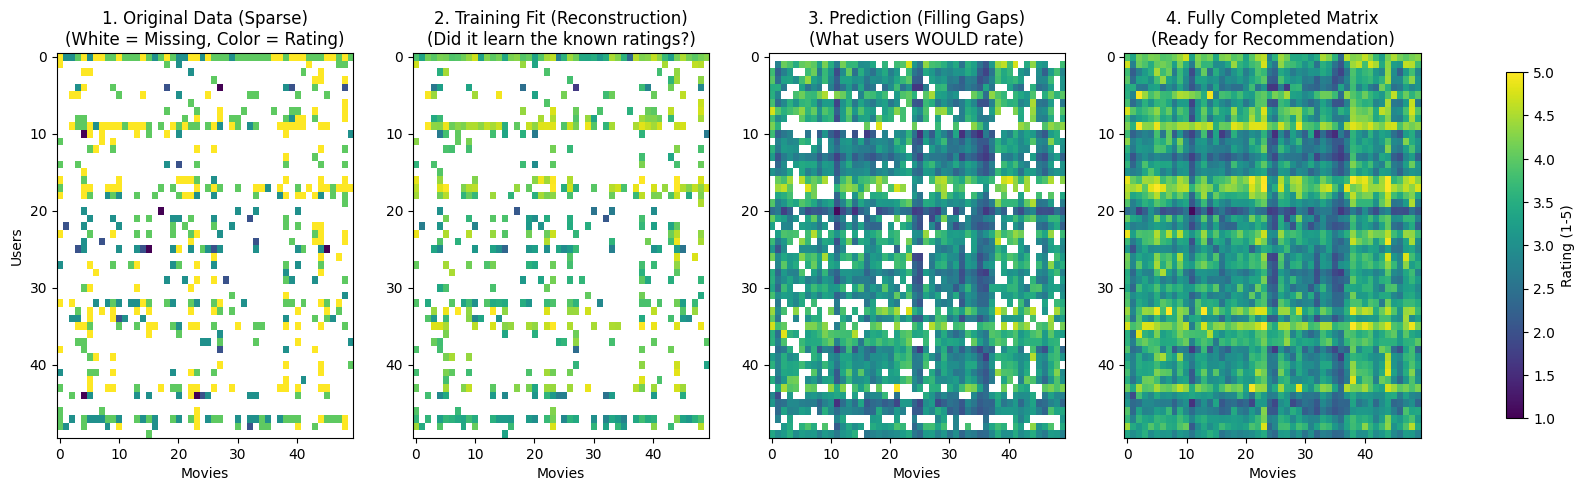


Loading movie titles...

--- Recommendations for User 1 ---
1. Fantasia 2000 (1999) (Score: 4.65)
2. Lion King, The (1994) (Score: 4.55)
3. Shawshank Redemption, The (1994) (Score: 4.45)
4. Forrest Gump (1994) (Score: 4.33)
5. Lady and the Tramp (1955) (Score: 4.30)

--- Movies Rated by User 1 (Top 10 Real Ratings) ---
- One Flew Over the Cuckoo's Nest (1975) (Real Rating: 5)
- Bug's Life, A (1998) (Real Rating: 5)
- Beauty and the Beast (1991) (Real Rating: 5)
- Christmas Story, A (1983) (Real Rating: 5)
- Ben-Hur (1959) (Real Rating: 5)
- Awakenings (1990) (Real Rating: 5)
- Sound of Music, The (1965) (Real Rating: 5)
- Toy Story (1995) (Real Rating: 5)
- Rain Man (1988) (Real Rating: 5)
- Last Days of Disco, The (1998) (Real Rating: 5)

Compare these with the recommendations generated above for User 1 to assess their sensibility.


In [ ]:
# ==============================================================================
# PHASE 4: DIAGNOSTIC VISUALIZATION (THE 4 PANELS) & RECOMMENDATION
# ==============================================================================

def visualize_model_behavior(R_sparse, U, V, zoom_size=50):
    """
    Diagnostic 4-panel visualization.
    Shows separately what the model "knows" and what it "hallucinates".
    """
    slice_R = R_sparse.tocsr()[:zoom_size, :zoom_size].toarray()
    slice_U = U[:zoom_size, :]
    slice_V = V[:zoom_size, :]

    slice_pred = np.dot(slice_U, slice_V.T)

    mask_known = (slice_R != 0)
    mask_missing = (slice_R == 0)

    fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(22, 5))

    cmap = plt.cm.viridis
    cmap.set_bad(color='white')

    # --- PLOT 1: Original Data ---
    visual_orig = slice_R.astype(float)
    visual_orig[mask_missing] = np.nan

    im1 = axes[0].imshow(visual_orig, cmap=cmap, aspect='auto', interpolation='nearest', vmin=1, vmax=5)
    axes[0].set_title("1. Original Data (Sparse)\n(White = Missing, Color = Rating)")
    axes[0].set_xlabel("Movies")
    axes[0].set_ylabel("Users")

    # --- PLOT 2: Reconstruction (Training Fit) ---
    visual_known = slice_pred.copy()
    visual_known[mask_missing] = np.nan

    axes[1].imshow(visual_known, cmap=cmap, aspect='auto', interpolation='nearest', vmin=1, vmax=5)
    axes[1].set_title("2. Training Fit (Reconstruction)\n(Did it learn the known ratings?)")
    axes[1].set_xlabel("Movies")

    # --- PLOT 3: "Hallucination" (Prediction) ---
    visual_missing = slice_pred.copy()
    visual_missing[mask_known] = np.nan

    axes[2].imshow(visual_missing, cmap=cmap, aspect='auto', interpolation='nearest', vmin=1, vmax=5)
    axes[2].set_title("3. Prediction (Filling Gaps)\n(What users WOULD rate)")
    axes[2].set_xlabel("Movies")

    # --- PLOT 4: Fully Completed Matrix ---
    axes[3].imshow(slice_pred, cmap=cmap, aspect='auto', interpolation='nearest', vmin=1, vmax=5)
    axes[3].set_title("4. Fully Completed Matrix\n(Ready for Recommendation)")
    axes[3].set_xlabel("Movies")

    fig.colorbar(im1, ax=axes.ravel().tolist(), shrink=0.9, label="Rating (1-5)")
    plt.show()

print("\nGenerating Diagnostic Plots...")
if 'U_opt' in locals() and 'V_opt' in locals():
    visualize_model_behavior(R_sparse, U_opt, V_opt, zoom_size=50)
else:
    print("Error: U_opt and V_opt not found!")

# ------------------------------------------------------------------------------
# RECOMMENDATION SYSTEM
# ------------------------------------------------------------------------------
print("\nLoading movie titles...")
movies_df = pd.read_csv('ml-1m/movies.dat', sep='::', engine='python',
                        encoding='latin-1', header=None, names=['movieId', 'title', 'genres'])
idx_to_movieID = {v: k for k, v in movie_to_idx.items()}

def recommend_movies(user_id_real, U, V, n=5):
    if user_id_real not in user_to_idx: return
    u_idx = user_to_idx[user_id_real]

    preds = np.dot(U[u_idx, :], V.T)

    user_mask = ratings_df['userId'] == user_id_real
    seen_ids = ratings_df[user_mask]['movieId'].unique()
    seen_idxs = [movie_to_idx[mid] for mid in seen_ids if mid in movie_to_idx]
    preds[seen_idxs] = -np.inf

    top_idxs = np.argsort(preds)[-n:][::-1]

    print(f"\n--- Recommendations for User {user_id_real} ---")
    for i, idx in enumerate(top_idxs):
        real_id = idx_to_movieID[idx]
        title = movies_df[movies_df['movieId']==real_id]['title'].values[0]
        print(f"{i+1}. {title} (Score: {preds[idx]:.2f})")

recommend_movies(1, U_opt, V_opt)

user1_real_id = 1
user1_ratings = ratings_df[ratings_df['userId'] == user1_real_id].copy()
user1_ratings = user1_ratings.sort_values(by='rating', ascending=False)
user1_ratings = user1_ratings.merge(movies_df[['movieId', 'title']], on='movieId', how='left')

print(f"\n--- Movies Rated by User {user1_real_id} (Top 10 Real Ratings) ---")
for index, row in user1_ratings.head(10).iterrows():
    print(f"- {row['title']} (Real Rating: {row['rating']})")

print("\nCompare these with the recommendations generated above for User 1 to assess their sensibility.")